First, we need to import all the necessary libraries:

In [24]:
import sys
sys.path.append("../src/focalseriesrecon")

import numpy as np
import torch

from utils import *
from optics import *
from specimen import *

We can now generate a phase object from an image by using the Specimen class.

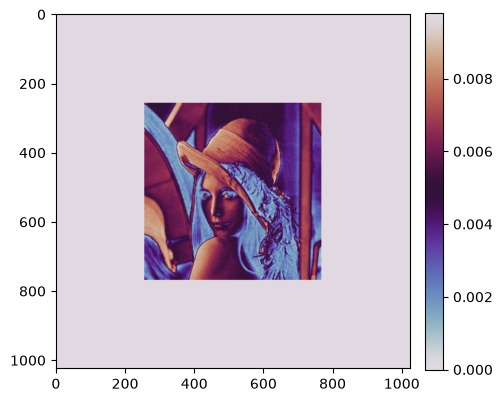

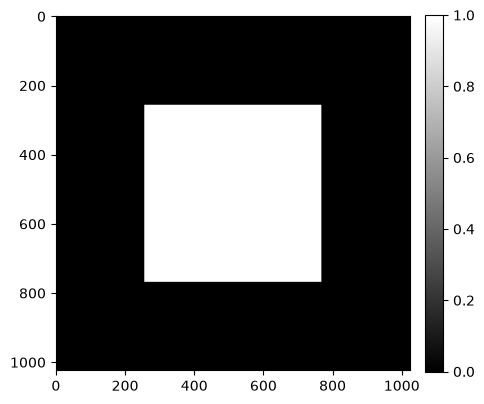

In [25]:
spec = Specimen(phase_source='../images/lena_1.jpg', phase_strength=0.01, resize_img=512, pixel_size=0.05)
ax1 = plot_2d(spec.owf, mode="phase")
ax2 = plot_2d(spec.owf, mode="abs")

Since we are working with a pure phase object, we cannot see any contrast when measuring the intensity. However, the phase contrast function will cause this to change:

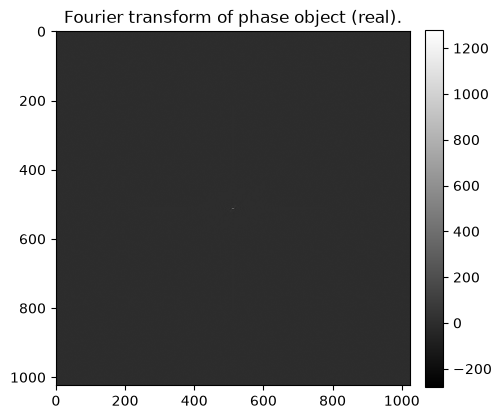

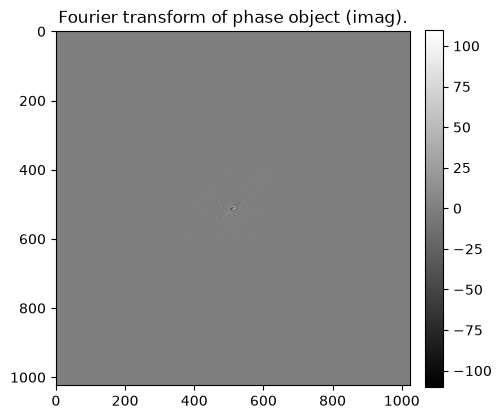

In [26]:
img_fourier = fft2d(torch.tensor(np.imag(spec.owf)))
ax3 = plot_2d(img_fourier, mode="real", title="Fourier transform of phase object (real).")
ax4 = plot_2d(img_fourier, mode="imag", title="Fourier transform of phase object (imag).")

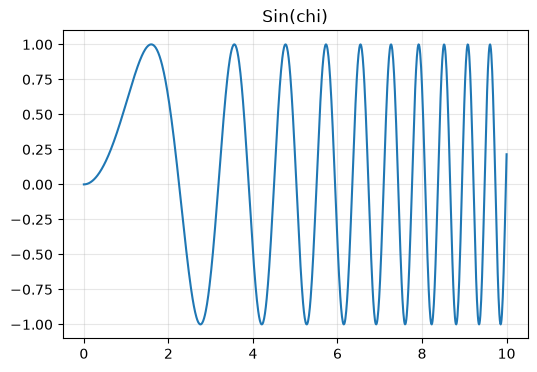

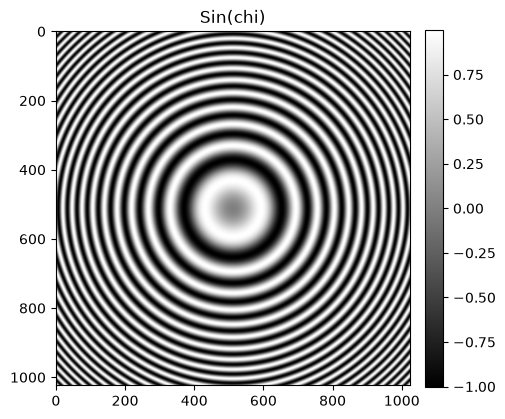

In [27]:
wavelength = electron_wavelength(300)
cs=1e4
defocus=100

k_values_1d = torch.tensor(np.linspace(0, 10, 1000))
ctf_values_1d = torch.sin(phase_error(k_values_1d, wavelength, defocus, cs))
ax5 = plot_1d(ctf_values_1d, k_values_1d, title="Sin(chi)")

ctf_values_2d = torch.sin(torch.tensor(phase_error(spec.k_grid, wavelength, defocus, cs)))
ax6 = plot_2d(ctf_values_2d, title="Sin(chi)")

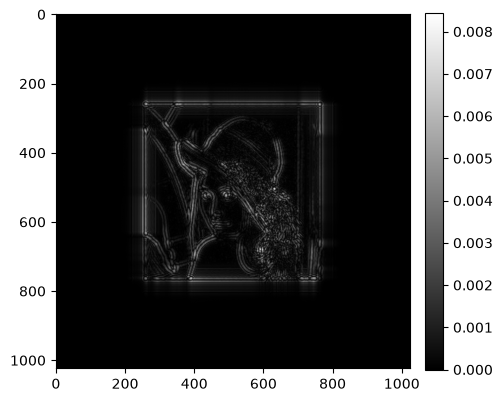

In [28]:
I_g = 2 * img_fourier * ctf_values_2d
I = ifft2d(I_g)
ax7 = plot_2d(I)
